# 09 - Robustness testing

Fold-to-fold stability, the A-versus-B comparison, and the stability of permutation importance.

In [1]:
import json, sys, pathlib
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

METRICS = ROOT / "evaluation" / "metrics"
PRED = ROOT / "evaluation" / "predictions"
PLOTS = ROOT / "evaluation" / "plots"
ERRORS = ROOT / "evaluation" / "error_analysis"

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def show(path):
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except Exception:
        print("plot written to", path)


## Fold stability

Coefficient of variation of fold MAE. A low value means performance does not depend on which states happen to be held out.

In [2]:
stability = pd.read_csv(METRICS / "phase3_fold_stability.csv")
stability.sort_values(["configuration", "mae_cv"]).groupby("configuration").head(5).round(4)

,configuration,model,mae_mean,mae_sd,mae_cv
0,A_primary_640,extra_trees,2.0919,0.1399,0.0669
1,A_primary_640,dummy_mean,2.4402,0.1656,0.0678
2,A_primary_640,svr_rbf,2.0293,0.1664,0.0820
3,A_primary_640,random_forest,2.1128,0.1764,0.0835
4,A_primary_640,ridge,2.1877,0.2400,0.1097
10,A_restricted_628,gradient_boosting,2.1426,0.1062,0.0496
11,A_restricted_628,extra_trees,2.0888,0.1084,0.0519
12,A_restricted_628,random_forest,2.0991,0.1244,0.0593
13,A_restricted_628,hist_gradient_boosting,2.1506,0.1607,0.0747
14,A_restricted_628,ridge,2.1845,0.1701,0.0779


In [3]:
stability.sort_values(["configuration", "mae_cv"]).groupby("configuration").tail(3).round(4)

,configuration,model,mae_mean,mae_sd,mae_cv
7,A_primary_640,decision_tree,2.4960,0.3460,0.1386
8,A_primary_640,elastic_net,2.2541,0.3261,0.1446
9,A_primary_640,knn,2.1636,0.3826,0.1768
17,A_restricted_628,svr_rbf,2.1714,0.2357,0.1086
18,A_restricted_628,decision_tree,2.2528,0.2673,0.1187
19,A_restricted_628,knn,2.1460,0.2898,0.1350
27,B_augmented_628,gradient_boosting,1.8677,0.1976,0.1058
28,B_augmented_628,hist_gradient_boosting,1.8413,0.2769,0.1504
29,B_augmented_628,decision_tree,2.5055,0.5869,0.2343


## A versus B on the same 628 districts

In [4]:
ab = pd.read_csv(METRICS / "phase3_ab_comparison.csv")
print(ab.round(3).to_string(index=False))
print()
print("models where B is better in all five folds:", int((ab["b_better_folds"] == 5).sum()), "of", len(ab))
print("models where A is better on average:", int((ab["delta_mean"] > 0).sum()), "of", len(ab))

                 model  a_mae  b_mae  delta_mean  delta_sd  b_better_folds  n_folds  delta_pct
           elastic_net  2.196  1.748      -0.449     0.124               5        5    -20.429
               svr_rbf  2.171  1.725      -0.447     0.166               5        5    -20.564
                 ridge  2.185  1.749      -0.435     0.104               5        5    -19.935
hist_gradient_boosting  2.151  1.841      -0.309     0.269               4        5    -14.382
                   knn  2.146  1.863      -0.283     0.256               5        5    -13.173
           extra_trees  2.089  1.810      -0.279     0.090               5        5    -13.344
     gradient_boosting  2.143  1.868      -0.275     0.168               5        5    -12.831
         random_forest  2.099  1.871      -0.228     0.063               5        5    -10.874
            dummy_mean  2.450  2.450       0.000     0.000               0        5      0.000
         decision_tree  2.253  2.506       0.253  

## Permutation importance, measured on held-out folds

Importance is the MAE increase when a feature is shuffled on the held-out districts, refitted per fold with that fold's chosen hyperparameters.

In [5]:
importance = pd.read_csv(METRICS / "phase3_permutation_importance.csv")
importance[importance["configuration"] == "B_augmented_628"].head(15)[
    ["rank", "feature", "importance_mean", "importance_sd", "n_folds_positive", "rank_mean", "rank_sd"]
].round(4).to_string(index=False)

' rank                   feature  importance_mean  importance_sd  n_folds_positive  rank_mean  rank_sd\n    1                  tv_share           0.0836         0.0837                 5        6.2   4.0866\n    2           hh_size_2_share           0.0609         0.0485                 4       15.8  26.5650\n    3         mobile_only_share           0.0527         0.0320                 5        9.4   8.5907\n    4            tapwater_share           0.0434         0.0158                 5       10.6   6.8775\n    5           telephone_share           0.0385         0.0282                 5       14.4  12.4016\n    6             scooter_share           0.0384         0.0485                 4       27.4  31.0048\n    7  other_cooking_fuel_share           0.0373         0.0407                 4       23.0  22.5942\n    8         electricity_share           0.0307         0.0389                 4       24.4  17.1406\n    9      uncovered_well_share           0.0284         0.0306         

## Which features survive in every fold?

In [6]:
stable_features = (importance[importance["n_folds_positive"] == 5]
                   .groupby("configuration")["feature"].apply(lambda s: list(s)))
for configuration, features in stable_features.items():
    print(f"{configuration}: {len(features)} features positive in all 5 folds")
    print("   ", features[:12])

A_primary_640: 6 features positive in all 5 folds
    ['owned_share_of_reported_tenure', 'secondary_share', 'hh_size_1_share', 'higher_share', 'age_not_stated_share', 'literacy_rate_male']
A_restricted_628: 6 features positive in all 5 folds
    ['worker_share', 'higher_share', 'hh_size_1_share', 'secondary_share', 'income_150k_240k_share', 'literacy_rate_male']
B_augmented_628: 10 features positive in all 5 folds
    ['tv_share', 'mobile_only_share', 'tapwater_share', 'telephone_share', 'tubewell_borehole_share', 'secondary_share', 'below_primary_share', 'income_below_45k_share', 'hh_size_1_share', 'multi_asset_share']


## Importance stability

`rank_sd` is the SD of a feature's importance rank across folds. Large values mean the ranking depends on the fold, usually because the feature is correlated with another member of the same block.

mean rank_sd among top-10 features: 13.43
top-10 features positive in all folds: 11 of 30


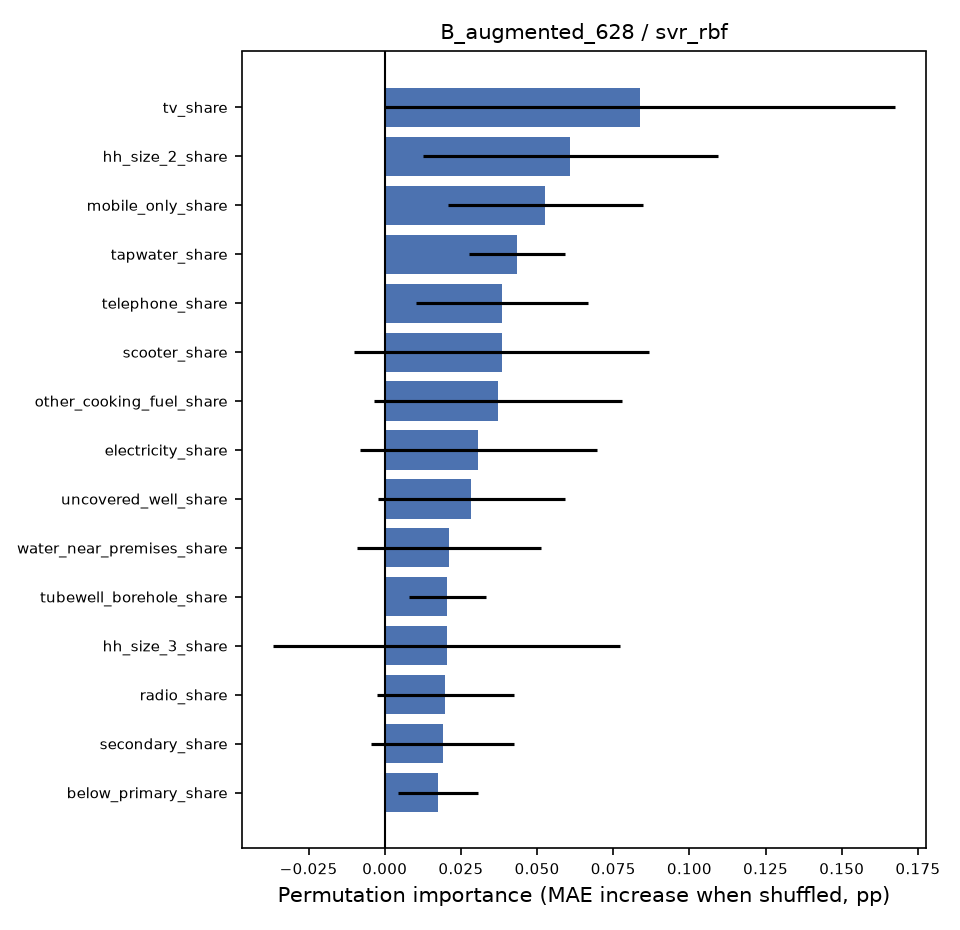

In [7]:
top = importance[importance["rank"] <= 10]
print("mean rank_sd among top-10 features:", round(float(top["rank_sd"].mean()), 2))
print("top-10 features positive in all folds:", int((top["n_folds_positive"] == 5).sum()), "of", len(top))
path = PLOTS / "phase3_importance_b628.png"
show(path)

## Reading these numbers

Permutation importance is a predictive association under correlation, not a causal effect. Several predictors are shares of the same household universe, so shuffling one leaves its information partly available through another.